<a href="https://colab.research.google.com/github/Angeltt251/Lab_2_10_Clustering/blob/main/Lab_2_10_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧩 Actividad 2.10 — Laboratorio de Clustering: K-means y jerárquico

**Asignatura:** IEI097 Minería de Datos · Unidad II  
**Autor:** José Miguel Flores Chávez · Instituto Profesional Santo Tomás  
**Tipo:** laboratorio individual en Google Colab

**Contenido:** Entorno · Ejercicio 1 (K-means, clientes de una tienda) · Ejercicio 2 (dendrograma, países) · Conclusión final

> Los datasets se descargan con `kagglehub`. Las credenciales se leen desde **Colab Secrets** (`KAGGLE_USERNAME` y `KAGGLE_KEY`) y nunca se escriben en el notebook.

**Regla de lectura:** un cluster significa «estas observaciones son cercanas bajo estas variables, esta transformación, esta distancia y estos parámetros».

## Entorno

In [1]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)

SEED = 42
N_INIT = 10
print("pandas:", pd.__version__)

pandas: 2.2.3


In [2]:
try:
    from google.colab import userdata
    os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
    os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
    print("Credenciales de Kaggle cargadas desde Colab Secrets ✅")
except Exception as e:
    print("No pude leer los Secrets de Colab (KAGGLE_USERNAME y KAGGLE_KEY). Revisa que existan y que el acceso desde el notebook esté activado.")
    print("Detalle:", type(e).__name__)

No pude leer los Secrets de Colab (KAGGLE_USERNAME y KAGGLE_KEY). Revisa que existan y que el acceso desde el notebook esté activado.
Detalle: SecretNotFoundError


In [3]:
def descargar_dataset(handle):
    carpeta = kagglehub.dataset_download(handle)
    archivos = sorted(glob.glob(os.path.join(carpeta, "**", "*.csv"), recursive=True))
    print("Dataset:", handle)
    for a in archivos:
        print(f" - {os.path.relpath(a, carpeta)} ({os.path.getsize(a) / 1e3:.1f} KB)")
    return archivos


def elegir_csv(archivos, pista=None):
    if pista:
        coincidencias = [a for a in archivos if pista.lower() in os.path.basename(a).lower()]
        if coincidencias:
            return coincidencias[0]
    return max(archivos, key=os.path.getsize)


def a_dataframe(matriz, referencia):
    return pd.DataFrame(matriz, columns=referencia.columns, index=referencia.index)


def dibujar_dendrograma(Z, etiquetas, ax, titulo, corte=None):
    dendrogram(Z, labels=list(etiquetas), orientation="right", ax=ax, leaf_font_size=9,
               color_threshold=corte if corte is not None else None, above_threshold_color="gray")
    ax.set_title(titulo)
    ax.set_xlabel("Altura de fusión (disimilitud)")
    if corte is not None:
        ax.axvline(corte, color="black", linestyle="--", linewidth=1.2)
    for etiqueta in ax.get_yticklabels():
        if etiqueta.get_text() == "Chile":
            etiqueta.set_color("red")
            etiqueta.set_fontweight("bold")

## Ejercicio 1 · K-means: segmentar clientes de una tienda

Caso: una tienda regional quiere diseñar comunicaciones diferenciadas. Aquí no existe una «clase correcta»: existe una hipótesis de segmento que debo poder defender.

### Paso 1 · Hipótesis antes de calcular

La carga del dataset va aquí porque el gráfico la necesita; la exploración completa está en el paso 2.

In [4]:
archivos_mall = descargar_dataset("vjchoudhary7/customer-segmentation-tutorial-in-python")
csv_mall = elegir_csv(archivos_mall, pista="mall")
print("\nCSV principal elegido:", os.path.basename(csv_mall))

df_mall = pd.read_csv(csv_mall)
COL_INGRESO = "Annual Income (k$)"
COL_GASTO = "Spending Score (1-100)"
COL_GENERO = next(c for c in df_mall.columns if c.lower() in ("gender", "genre"))
assert COL_INGRESO in df_mall.columns and COL_GASTO in df_mall.columns, f"Columnas disponibles: {list(df_mall.columns)}"

print("Dimensiones:", df_mall.shape)
df_mall.head()

Using Colab cache for faster access to the 'customer-segmentation-tutorial-in-python' dataset.
Dataset: vjchoudhary7/customer-segmentation-tutorial-in-python
 - Mall_Customers.csv (4.0 KB)

CSV principal elegido: Mall_Customers.csv
Dimensiones: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


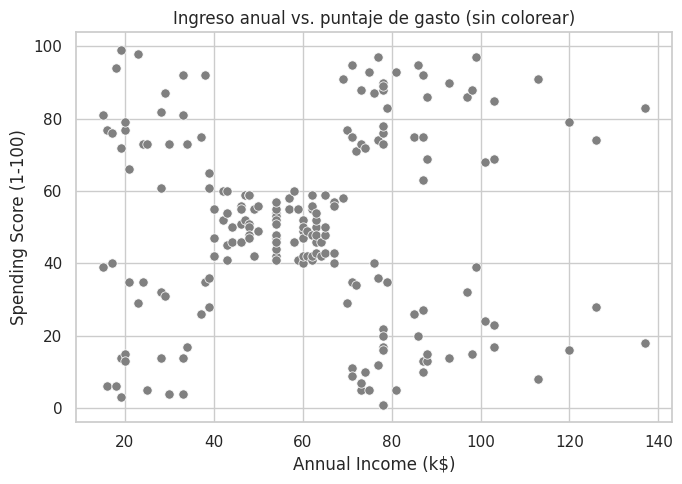

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=df_mall, x=COL_INGRESO, y=COL_GASTO, color="gray", s=45, ax=ax)
ax.set_title("Ingreso anual vs. puntaje de gasto (sin colorear)")
plt.tight_layout()
plt.show()

### Paso 2 · Cargar y explorar

In [6]:
df_mall.info()
print("\nValores nulos por columna:")
print(df_mall.isna().sum().to_string())
print(f"\nFilas duplicadas: {int(df_mall.duplicated().sum())}")
print(f"\nDistribución de {COL_GENERO}:")
print(df_mall[COL_GENERO].value_counts().to_string())
df_mall.describe().round(2)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB

Valores nulos por columna:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0

Filas duplicadas: 0

Distribución de Gender:
Gender
Female    112
Male       88


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.00,200.00,200.00,200.00
mean,100.50,38.85,60.56,50.20
std,57.88,13.97,26.26,25.82
min,1.00,18.00,15.00,1.00
25%,50.75,28.75,41.50,34.75
50%,100.50,36.00,61.50,50.00
75%,150.25,49.00,78.00,73.00
max,200.00,70.00,137.00,99.00


In [ ]:
numericas_mall = [c for c in df_mall.select_dtypes("number").columns if c != "CustomerID"]
fig, ejes = plt.subplots(2, len(numericas_mall), figsize=(4.4 * len(numericas_mall), 6))
for j, col in enumerate(numericas_mall):
    sns.histplot(df_mall[col], kde=True, ax=ejes[0, j], color="#4C72B0")
    ejes[0, j].set_title(f"Distribución de {col}")
    sns.boxplot(x=df_mall[col], ax=ejes[1, j], color="#DD8452")
    ejes[1, j].set_title(f"Box-plot de {col}")
plt.tight_layout()
plt.show()

### Paso 3 · Preparar: variables y escala

Empiezo con ingreso y puntaje de gasto para poder visualizar en 2D. Conservo la versión original y la estandarizada, porque las comparo en el paso 5.

In [ ]:
VARS_K = [COL_INGRESO, COL_GASTO]

X_orig = df_mall[VARS_K].copy()
rangos = X_orig.agg(["min", "max"]).T
rangos["amplitud"] = rangos["max"] - rangos["min"]
print("Rango de cada variable antes de escalar:")
display(rangos)

escalador_mall = StandardScaler()
X_std = a_dataframe(escalador_mall.fit_transform(X_orig), X_orig)
print("\nDespués de estandarizar (media ≈ 0 y desviación estándar ≈ 1):")
X_std.agg(["mean", "std"]).round(3)

### Paso 4 · Ajustar K-means y explorar k

Ajusto K-means para k de 2 a 10 sobre los datos estandarizados, con `n_init` y `random_state` fijos, y registro la inercia y el coeficiente de silueta.

In [ ]:
resultados_k = []
for k in range(2, 11):
    modelo = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(X_std)
    resultados_k.append({"k": k, "inercia": modelo.inertia_, "silueta": silhouette_score(X_std, modelo.labels_)})
tabla_k = pd.DataFrame(resultados_k)

fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2))
ejes[0].plot(tabla_k["k"], tabla_k["inercia"], marker="o")
ejes[0].set_title("Inercia vs. k (método del codo)")
ejes[0].set_xlabel("k")
ejes[0].set_ylabel("Inercia")
ejes[1].plot(tabla_k["k"], tabla_k["silueta"], marker="o", color="#55A868")
ejes[1].set_title("Coeficiente de silueta vs. k")
ejes[1].set_xlabel("k")
ejes[1].set_ylabel("Silueta promedio")
for ax in ejes:
    ax.set_xticks(tabla_k["k"])
plt.tight_layout()
plt.show()

tabla_k.round(4)

### Paso 5 · Evaluar con más de una evidencia

Tres tipos de evidencia: (a) estructura interna (codo y silueta), (b) estabilidad y (c) utilidad. Más un mini-experimento de escala.

**(a) Estructura interna.** El `k` de partida es el de mayor silueta. **Es solo un punto de partida:** cámbialo en la celda siguiente por el k que tú decidas después de ver todas las evidencias.

In [ ]:
K_ELEGIDO = int(tabla_k.loc[tabla_k["silueta"].idxmax(), "k"])
print("k con mayor silueta:", K_ELEGIDO)

modelo_ref = KMeans(n_clusters=K_ELEGIDO, n_init=N_INIT, random_state=SEED).fit(X_std)
etiquetas_ref = modelo_ref.labels_
print("Tamaño de cada grupo:", np.bincount(etiquetas_ref).tolist())

**(b) Estabilidad.** Si los grupos son reales, deberían persistir al cambiar la semilla o al quitar parte de los datos. Lo mido con el índice de Rand ajustado (ARI): 1 significa que las asignaciones son idénticas y cerca de 0, que son tan distintas como el azar.

In [ ]:
ari_semillas = []
for s in range(100, 130):
    etiquetas_s = KMeans(n_clusters=K_ELEGIDO, n_init=1, random_state=s).fit_predict(X_std)
    ari_semillas.append(adjusted_rand_score(etiquetas_ref, etiquetas_s))

ari_submuestras = []
for s in range(30):
    submuestra = X_std.sample(frac=0.8, random_state=s)
    modelo_s = KMeans(n_clusters=K_ELEGIDO, n_init=N_INIT, random_state=SEED).fit(submuestra)
    ari_submuestras.append(adjusted_rand_score(etiquetas_ref, modelo_s.predict(X_std)))

estabilidad = pd.DataFrame({
    "prueba": [f"30 semillas distintas (n_init=1), k = {K_ELEGIDO}", f"30 submuestras del 80 %, k = {K_ELEGIDO}"],
    "ARI promedio": [np.mean(ari_semillas), np.mean(ari_submuestras)],
    "ARI mínimo": [np.min(ari_semillas), np.min(ari_submuestras)],
})
estabilidad.round(4)

In [ ]:
estabilidad_por_k = []
for k in range(2, 11):
    ref_k = KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(X_std).labels_
    aris = []
    for s in range(20):
        sub = X_std.sample(frac=0.8, random_state=s)
        aris.append(adjusted_rand_score(ref_k, KMeans(n_clusters=k, n_init=N_INIT, random_state=SEED).fit(sub).predict(X_std)))
    estabilidad_por_k.append({"k": k, "ARI promedio (submuestras)": np.mean(aris), "ARI mínimo": np.min(aris)})

comparativa_k = tabla_k.merge(pd.DataFrame(estabilidad_por_k), on="k")
comparativa_k.round(4)

In [ ]:
modelo_sin_escala = KMeans(n_clusters=K_ELEGIDO, n_init=N_INIT, random_state=SEED).fit(X_orig)
etiquetas_sin_escala = modelo_sin_escala.labels_

ari_escala = adjusted_rand_score(etiquetas_ref, etiquetas_sin_escala)
print(f"ARI entre la partición estandarizada y la no estandarizada (k = {K_ELEGIDO}): {ari_escala:.4f}")
print("Tamaños (estandarizado)    :", np.bincount(etiquetas_ref).tolist())
print("Tamaños (sin estandarizar) :", np.bincount(etiquetas_sin_escala).tolist())

print("\nTabla de contingencia (filas: estandarizado, columnas: sin estandarizar):")
display(pd.crosstab(pd.Series(etiquetas_ref, name="estandarizado"), pd.Series(etiquetas_sin_escala, name="sin estandarizar")))

fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
for ax, etiquetas, titulo in zip(ejes, [etiquetas_ref, etiquetas_sin_escala], ["Con estandarizar", "Sin estandarizar"]):
    sns.scatterplot(x=X_orig[COL_INGRESO], y=X_orig[COL_GASTO], hue=etiquetas, palette="tab10", s=45, ax=ax, legend=False)
    ax.set_title(f"K-means, k = {K_ELEGIDO}: {titulo.lower()}")
plt.tight_layout()
plt.show()

### Paso 6 · Interpretar y decidir

In [ ]:
df_mall["cluster"] = modelo_ref.labels_

perfil_mall = df_mall.groupby("cluster").agg(
    clientes=(COL_INGRESO, "size"),
    ingreso_media=(COL_INGRESO, "mean"),
    ingreso_mediana=(COL_INGRESO, "median"),
    gasto_media=(COL_GASTO, "mean"),
    gasto_mediana=(COL_GASTO, "median"),
    edad_media=("Age", "mean"),
)
perfil_mall["% de clientes"] = perfil_mall["clientes"] / len(df_mall) * 100
perfil_mall.round(2)

In [ ]:
centros = pd.DataFrame(escalador_mall.inverse_transform(modelo_ref.cluster_centers_), columns=VARS_K)

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=df_mall, x=COL_INGRESO, y=COL_GASTO, hue="cluster", palette="tab10", s=55, ax=ax)
ax.scatter(centros[COL_INGRESO], centros[COL_GASTO], marker="X", s=260, c="black", edgecolor="white", linewidth=1.5, label="centroides")
for i, fila in centros.iterrows():
    ax.annotate(str(i), (fila[COL_INGRESO], fila[COL_GASTO]), xytext=(8, 8), textcoords="offset points", fontsize=12, fontweight="bold")
ax.set_title(f"K-means (k = {K_ELEGIDO}) en unidades originales")
ax.legend(title="cluster", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

centros.round(2)

## Ejercicio 2 · Clustering jerárquico: ¿con qué países se parece Chile?

Caso: una organización de cooperación quiere entender qué países se parecen en indicadores socioeconómicos y de salud, y a qué nivel de detalle conviene agruparlos. Pregunta guía: ¿con qué países se agrupa Chile y a qué nivel de la jerarquía?

### Paso 1 · Hipótesis y muestra de trabajo

In [ ]:
archivos_paises = descargar_dataset("rohan0301/unsupervised-learning-on-country-data")
csv_paises = elegir_csv(archivos_paises, pista="country")
print("\nCSV principal elegido:", os.path.basename(csv_paises))

df_paises = pd.read_csv(csv_paises)
print("Dimensiones:", df_paises.shape)
print("\nNombres de países disponibles:")
print(" | ".join(sorted(df_paises["country"].unique())))

In [ ]:
AMERICA_LATINA = ["Argentina", "Bolivia", "Brazil", "Chile", "Colombia", "Costa Rica", "Dominican Republic", "Ecuador", "El Salvador",
                  "Guatemala", "Guyana", "Haiti", "Honduras", "Jamaica", "Mexico", "Nicaragua", "Panama", "Paraguay", "Peru",
                  "Suriname", "Uruguay", "Venezuela", "Belize", "Bahamas", "Barbados", "Trinidad and Tobago"]
REFERENCIA = ["United States", "Canada", "Spain", "Portugal", "Germany", "Norway", "Japan", "China", "India", "Nigeria",
              "South Africa", "Turkey", "Australia", "Italy"]

disponibles = set(df_paises["country"])
solicitados = AMERICA_LATINA + REFERENCIA
subconjunto = [p for p in solicitados if p in disponibles]
no_encontrados = [p for p in solicitados if p not in disponibles]

if len(subconjunto) < 25:
    complemento = df_paises[~df_paises["country"].isin(subconjunto)]["country"].sample(30 - len(subconjunto), random_state=SEED).tolist()
    subconjunto = subconjunto + complemento
    print("Se completó con una muestra aleatoria reproducible:", complemento)

assert "Chile" in subconjunto, "Chile no está en el subconjunto: revisa cómo está escrito en la lista de nombres."
print(f"Países en el subconjunto: {len(subconjunto)}")
print("Nombres pedidos que no están en el dataset:", no_encontrados if no_encontrados else "ninguno")
print("\n" + " | ".join(sorted(subconjunto)))

### Paso 2 · Cargar y explorar

In [ ]:
df_paises.info()
print("\nValores nulos por columna:")
print(df_paises.isna().sum().to_string())
print(f"\nPaíses duplicados: {int(df_paises['country'].duplicated().sum())}")

VARS_PAISES = [c for c in df_paises.columns if c != "country"]
magnitudes = df_paises[VARS_PAISES].agg(["min", "max", "mean", "std"]).T
magnitudes["max / mín. positivo"] = magnitudes["max"] / df_paises[VARS_PAISES].where(df_paises[VARS_PAISES] > 0).min()
magnitudes.round(2)

In [ ]:
fig, ejes = plt.subplots(2, 5, figsize=(20, 7))
for ax, col in zip(ejes.ravel(), VARS_PAISES):
    sns.boxplot(y=df_paises[col], ax=ax, color="#4C72B0")
    ax.set_title(col)
for ax in ejes.ravel()[len(VARS_PAISES):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(df_paises[VARS_PAISES].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Correlación entre indicadores (167 países)")
plt.tight_layout()
plt.show()

### Paso 3 · Preparar: ¿cuánto pesa cada variable?

Construyo dos matrices para el subconjunto: una con los valores originales y otra estandarizada. Los nombres de los países quedan como índice y etiquetas.

In [ ]:
df_sub = df_paises[df_paises["country"].isin(subconjunto)].set_index("country")
etiquetas_paises = df_sub.index.tolist()

X_pais_orig = df_sub[VARS_PAISES].copy()
escalador_paises = StandardScaler()
X_pais_std = a_dataframe(escalador_paises.fit_transform(X_pais_orig), X_pais_orig)

print(f"Subconjunto: {X_pais_orig.shape[0]} países x {X_pais_orig.shape[1]} variables")
print("\nDesviación estándar por variable, antes y después de estandarizar:")
pd.DataFrame({"original": X_pais_orig.std(), "estandarizada": X_pais_std.std()}).round(3)

### Paso 4 · Construir la jerarquía y leer el dendrograma

Cuatro tipos de enlace (single, complete, average y ward) sobre la matriz estandarizada. Chile aparece en rojo.

In [ ]:
ENLACES = ["single", "complete", "average", "ward"]
Z_std = {m: linkage(X_pais_std.values, method=m) for m in ENLACES}

fig, ejes = plt.subplots(2, 2, figsize=(17, max(12, 0.42 * len(etiquetas_paises) * 2)))
for ax, metodo in zip(ejes.ravel(), ENLACES):
    dibujar_dendrograma(Z_std[metodo], etiquetas_paises, ax, f"Enlace {metodo} (datos estandarizados)")
plt.tight_layout()
plt.show()

In [ ]:
cofenetica = []
for metodo in ENLACES:
    c, _ = cophenet(Z_std[metodo], pdist(X_pais_std.values))
    cofenetica.append({"enlace": metodo, "correlación cofenética": c})
pd.DataFrame(cofenetica).round(4)

Ahora repito un enlace sobre los datos **sin estandarizar** y lo comparo con su versión estandarizada. Elige el enlace que prefieras cambiando `ENLACE`.

In [ ]:
ENLACE = "ward"

Z_orig = linkage(X_pais_orig.values, method=ENLACE)

fig, ejes = plt.subplots(1, 2, figsize=(17, max(8, 0.42 * len(etiquetas_paises))))
dibujar_dendrograma(Z_std[ENLACE], etiquetas_paises, ejes[0], f"Enlace {ENLACE}: datos estandarizados")
dibujar_dendrograma(Z_orig, etiquetas_paises, ejes[1], f"Enlace {ENLACE}: datos sin estandarizar")
plt.tight_layout()
plt.show()

### Paso 5 · Cortar la jerarquía

El dendrograma no entrega grupos hasta que lo corto. Para cada número de grupos (2 a 5) calculo la altura de corte, el salto de altura que «sobrevive» ese corte, la silueta y los tamaños. Recuerda: la altura mide disimilitud, no calidad.

In [ ]:
Z = Z_std[ENLACE]
n_paises = len(X_pais_std)

evidencia_corte = []
etiquetas_por_k = {}
for k in range(2, 6):
    altura_inferior = Z[n_paises - 1 - k, 2]
    altura_superior = Z[n_paises - k, 2]
    etiquetas_k = fcluster(Z, t=k, criterion="maxclust")
    etiquetas_por_k[k] = etiquetas_k
    evidencia_corte.append({
        "grupos": k,
        "altura de corte": (altura_inferior + altura_superior) / 2,
        "salto de altura que sobrevive": altura_superior - altura_inferior,
        "silueta": silhouette_score(X_pais_std, etiquetas_k),
        "tamaños": np.bincount(etiquetas_k)[1:].tolist(),
    })
evidencia_corte = pd.DataFrame(evidencia_corte)
evidencia_corte.round(4)

In [ ]:
K_CORTE = int(evidencia_corte.loc[evidencia_corte["silueta"].idxmax(), "grupos"])
altura_corte = float(evidencia_corte.loc[evidencia_corte["grupos"] == K_CORTE, "altura de corte"].iloc[0])
print(f"Corte de partida: {K_CORTE} grupos (el de mayor silueta), altura {altura_corte:.3f}")

fig, ax = plt.subplots(figsize=(10, max(8, 0.42 * len(etiquetas_paises))))
dibujar_dendrograma(Z, etiquetas_paises, ax, f"Enlace {ENLACE}, corte en {K_CORTE} grupos", corte=altura_corte)
plt.tight_layout()
plt.show()

### Paso 6 · Interpretar y comparar con K-means

In [ ]:
df_sub_res = df_sub.copy()
df_sub_res["grupo_jerarquico"] = fcluster(Z, t=K_CORTE, criterion="maxclust")

for grupo, tabla in df_sub_res.groupby("grupo_jerarquico"):
    print(f"Grupo {grupo} ({len(tabla)} países): " + ", ".join(sorted(tabla.index)))

perfil_paises = df_sub_res.groupby("grupo_jerarquico")[VARS_PAISES].mean()
perfil_paises.insert(0, "países", df_sub_res.groupby("grupo_jerarquico").size())
perfil_paises.round(2)

In [ ]:
grupo_chile = df_sub_res.loc["Chile", "grupo_jerarquico"]
vecinos_chile = sorted(df_sub_res[df_sub_res["grupo_jerarquico"] == grupo_chile].index.difference(["Chile"]))
print(f"Chile está en el grupo {grupo_chile} del corte de {K_CORTE} grupos, junto con {len(vecinos_chile)} países:")
print(", ".join(vecinos_chile) if vecinos_chile else "ninguno (Chile queda solo)")

print("\nPaíses con los que Chile se agrupa según el número de grupos del corte:")
for k, etiquetas_k in etiquetas_por_k.items():
    serie = pd.Series(etiquetas_k, index=etiquetas_paises)
    companeros = sorted(serie[serie == serie["Chile"]].index.difference(["Chile"]))
    print(f"  {k} grupos: {len(companeros)} países")

In [ ]:
modelo_paises = KMeans(n_clusters=K_CORTE, n_init=N_INIT, random_state=SEED).fit(X_pais_std)
df_sub_res["grupo_kmeans"] = modelo_paises.labels_

print(f"Tabla de contingencia (k = {K_CORTE}): filas = jerárquico, columnas = K-means")
display(pd.crosstab(df_sub_res["grupo_jerarquico"], df_sub_res["grupo_kmeans"]))

ari_metodos = adjusted_rand_score(df_sub_res["grupo_jerarquico"], df_sub_res["grupo_kmeans"])
print(f"\nARI entre ambas particiones: {ari_metodos:.4f}")

grupo_chile_km = df_sub_res.loc["Chile", "grupo_kmeans"]
vecinos_chile_km = sorted(df_sub_res[df_sub_res["grupo_kmeans"] == grupo_chile_km].index.difference(["Chile"]))
print(f"\nChile en K-means: grupo {grupo_chile_km}, junto con: " + (", ".join(vecinos_chile_km) if vecinos_chile_km else "ninguno"))

diferentes = sorted(set(vecinos_chile) ^ set(vecinos_chile_km))
print("Países que acompañan a Chile en un método pero no en el otro:", ", ".join(diferentes) if diferentes else "ninguno")